<a href="https://colab.research.google.com/github/BintangPancahaya/PemMes_2026/blob/main/JS09/JS09_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Tugas Lab 1: Perbandingan ANNOY, FAISS, dan HNSW
Percobaan dilakukan pada:
- **Metric distance** yang berbeda: Euclidean dan Cosine (angular)
- **Jumlah data**: 1.000 vs 1.000.000
- **Dimensi**: 2D vs 5D

Setiap kombinasi diukur **build time** (waktu membangun index), **query time** (rata-rata dari 100 query, ms/query), dan **Recall@10** (berapa persen 10 tetangga terdekat yang sama dengan hasil exact NN/brute force).

### Install dan Import Library

In [ ]:
!pip install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 7.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 21.7 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520033 sha256=893131f6c8613d3a3f403cc8b05b3a81d8b0daa8a945e97a648e5da357ed06e6
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=cbaa30f5b773a69542240de64975b26b3e8d9674885ceafd52d685ac828c69d8
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

### Fungsi Percobaan
- **ANNOY**: 10 trees, metric `euclidean` / `angular`
- **FAISS**: `IndexIVFFlat` (nlist 10 untuk 1.000 data, 1.000 untuk 1.000.000 data, nprobe 5), metric L2 / inner product
- **HNSW**: hnswlib, `M=16`, `ef_construction=100`, `ef=50`, space `l2` / `cosine`

Untuk metric cosine, data dinormalisasi (panjang vektor = 1) sehingga inner product pada FAISS sama dengan cosine similarity.

In [ ]:
import numpy as np
import pandas as pd
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

k = 10          # jumlah tetangga terdekat yang dicari
n_query = 100   # jumlah query untuk menghitung rata-rata waktu & recall

def ground_truth(X, Q, metric):
    # Exact NN (brute force) sebagai acuan untuk menghitung recall
    d = X.shape[1]
    if metric == 'euclidean':
        index = faiss.IndexFlatL2(d)
    else:
        index = faiss.IndexFlatIP(d)  # data sudah dinormalisasi -> inner product = cosine
    index.add(X)
    _, I = index.search(Q, k)
    return I

def recall_at_k(I_pred, I_gt):
    benar = sum(len(set(I_pred[i]) & set(I_gt[i])) for i in range(len(I_gt)))
    return benar / (len(I_gt) * k)

def run_annoy(X, Q, metric):
    d = X.shape[1]
    index = AnnoyIndex(d, 'euclidean' if metric == 'euclidean' else 'angular')
    start = time.time()
    for i in range(len(X)):
        index.add_item(i, X[i])
    index.build(10)  # 10 trees
    build = time.time() - start
    start = time.time()
    I = [index.get_nns_by_vector(q, k) for q in Q]
    query = (time.time() - start) * 1000 / len(Q)
    return build, query, I

def run_faiss(X, Q, metric):
    d = X.shape[1]
    nlist = 10 if len(X) <= 10_000 else 1000
    if metric == 'euclidean':
        quantizer = faiss.IndexFlatL2(d)
        index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    else:
        quantizer = faiss.IndexFlatIP(d)
        index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_INNER_PRODUCT)
    start = time.time()
    index.train(X)
    index.add(X)
    build = time.time() - start
    index.nprobe = 5
    start = time.time()
    _, I = index.search(Q, k)
    query = (time.time() - start) * 1000 / len(Q)
    return build, query, I

def run_hnsw(X, Q, metric):
    d = X.shape[1]
    index = hnswlib.Index(space='l2' if metric == 'euclidean' else 'cosine', dim=d)
    start = time.time()
    index.init_index(max_elements=len(X), ef_construction=100, M=16)
    index.add_items(X)
    build = time.time() - start
    index.set_ef(50)
    start = time.time()
    I, _ = index.knn_query(Q, k=k)
    query = (time.time() - start) * 1000 / len(Q)
    return build, query, I

### Menjalankan Percobaan (2 metric × 2 jumlah data × 2 dimensi × 3 algoritma)

In [ ]:
hasil = []
for metric in ['euclidean', 'cosine']:
    for n_data in [1_000, 1_000_000]:
        for dim in [2, 5]:
            np.random.seed(42)
            X = np.random.random((n_data, dim)).astype(np.float32)
            Q = np.random.random((n_query, dim)).astype(np.float32)
            if metric == 'cosine':
                X = X / np.linalg.norm(X, axis=1, keepdims=True)
                Q = Q / np.linalg.norm(Q, axis=1, keepdims=True)
            gt = ground_truth(X, Q, metric)

            for nama, fungsi in [('ANNOY', run_annoy), ('FAISS', run_faiss), ('HNSW', run_hnsw)]:
                build, query, I = fungsi(X, Q, metric)
                hasil.append({'Metric': metric, 'Jumlah Data/Dimensi': f'{n_data}/{dim}D',
                              'Algoritma': nama, 'Build (s)': build,
                              'Query (ms/query)': query, 'Recall@10': recall_at_k(I, gt)})
            print(f'Selesai: {metric} | {n_data} data | {dim}D')

df_hasil = pd.DataFrame(hasil)

Selesai: euclidean | 1000 data | 2D
Selesai: euclidean | 1000 data | 5D
Selesai: euclidean | 1000000 data | 2D
Selesai: euclidean | 1000000 data | 5D
Selesai: cosine | 1000 data | 2D
Selesai: cosine | 1000 data | 5D
Selesai: cosine | 1000000 data | 2D
Selesai: cosine | 1000000 data | 5D


### Tabel Hasil Performa

In [ ]:
pd.set_option('display.float_format', '{:.4f}'.format)

for kolom in ['Query (ms/query)', 'Recall@10', 'Build (s)']:
    tabel = df_hasil.pivot_table(index=['Metric', 'Jumlah Data/Dimensi'], columns='Algoritma',
                                 values=kolom, sort=False)[['ANNOY', 'FAISS', 'HNSW']]
    print(f'\n===== {kolom} =====')
    display(tabel)


===== Query (ms/query) =====


Algoritma                      ANNOY  FAISS   HNSW
Metric    Jumlah Data/Dimensi                     
euclidean 1000/2D             0.0372 0.0432 0.0195
          1000/5D             0.0310 0.0651 0.0247
          1000000/2D          0.0664 0.0411 0.0382
          1000000/5D          0.0583 0.0439 0.0414
cosine    1000/2D             0.0226 0.0069 0.0093
          1000/5D             0.0258 0.0080 0.0278
          1000000/2D          0.0537 0.0588 0.0589
          1000000/5D          0.0609 0.0671 0.0353


===== Recall@10 =====


Algoritma                      ANNOY  FAISS   HNSW
Metric    Jumlah Data/Dimensi                     
euclidean 1000/2D             0.9940 1.0000 1.0000
          1000/5D             0.9600 0.9990 1.0000
          1000000/2D          0.9950 1.0000 1.0000
          1000000/5D          0.9490 0.9930 1.0000
cosine    1000/2D             0.9930 1.0000 0.9990
          1000/5D             0.9820 1.0000 1.0000
          1000000/2D          0.1600 0.9090 0.0270
          1000000/5D          0.9800 1.0000 0.9990


===== Build (s) =====


Algoritma                       ANNOY  FAISS     HNSW
Metric    Jumlah Data/Dimensi                        
euclidean 1000/2D              0.0393 0.1469   0.0611
          1000/5D              0.0342 0.1515   0.0753
          1000000/2D          36.6462 0.8764  60.7733
          1000000/5D          23.3262 1.1765  99.1545
cosine    1000/2D              0.0505 0.0011   0.0233
          1000/5D              0.0230 0.0012   0.0535
          1000000/2D          91.7018 2.6215 110.2455
          1000000/5D          29.8331 5.6480  91.7341

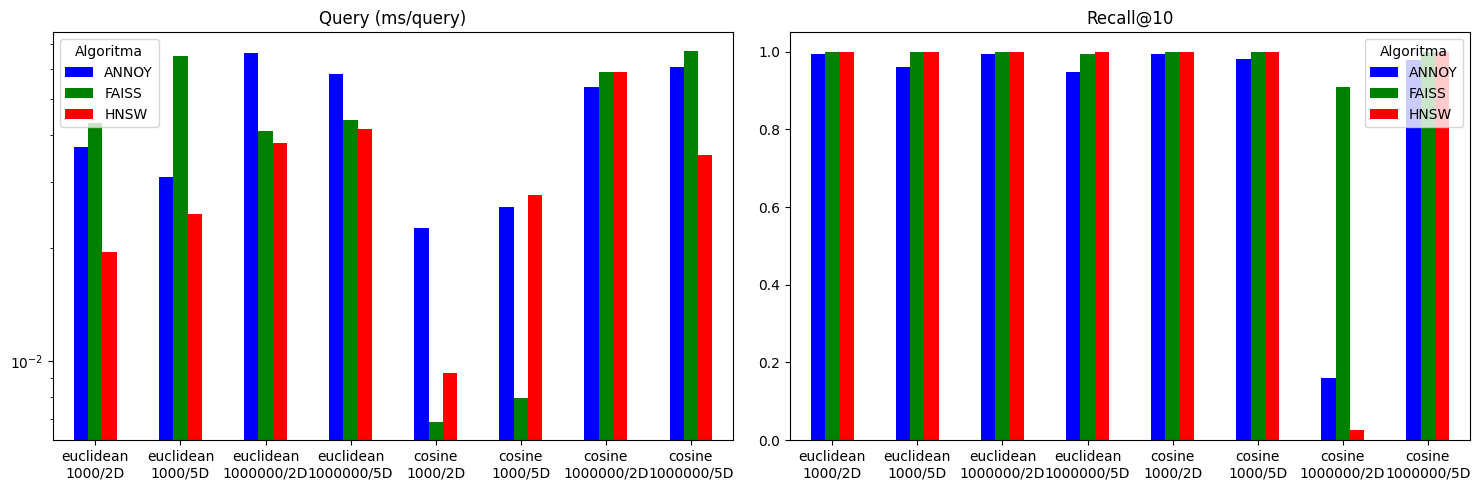

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, kolom in zip(axes, ['Query (ms/query)', 'Recall@10']):
    p = df_hasil.pivot_table(index=['Metric', 'Jumlah Data/Dimensi'], columns='Algoritma',
                             values=kolom, sort=False)[['ANNOY', 'FAISS', 'HNSW']]
    p.index = [f'{m}\n{d}' for m, d in p.index]
    p.plot(kind='bar', ax=ax, color=['blue', 'green', 'red'], rot=0)
    ax.set_title(kolom)
axes[0].set_yscale('log')
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Ringkasan Tabel dan Analisis

Nilai di tabel: **query time (ms/query) / Recall@10**. Build time ada di tabel *Build (s)* di atas.

| Metric | Jumlah Data/Dimensi | ANNOY | FAISS | HNSW |
|---|---|---|---|---|
| Euclidean | 1000/2D | 0,037 / 0,994 | 0,043 / 1,000 | 0,020 / 1,000 |
| Euclidean | 1000/5D | 0,031 / 0,960 | 0,065 / 0,999 | 0,025 / 1,000 |
| Euclidean | 1000000/2D | 0,066 / 0,995 | 0,041 / 1,000 | 0,038 / 1,000 |
| Euclidean | 1000000/5D | 0,058 / 0,949 | 0,044 / 0,993 | 0,041 / 1,000 |
| Cosine | 1000/2D | 0,023 / 0,993 | 0,007 / 1,000 | 0,009 / 0,999 |
| Cosine | 1000/5D | 0,026 / 0,982 | 0,008 / 1,000 | 0,028 / 1,000 |
| Cosine | 1000000/2D | 0,054 / 0,160 | 0,059 / 0,909 | 0,059 / 0,027 |
| Cosine | 1000000/5D | 0,061 / 0,980 | 0,067 / 1,000 | 0,035 / 0,999 |

**Analisis:**
- **Jumlah data (1.000 vs 1.000.000).** Pada 1.000 data ketiga algoritma sama-sama sangat cepat (puluhan mikrodetik) dan build-nya kurang dari 0,2 detik, jadi ANN belum terasa manfaatnya. Pada 1.000.000 data, query tetap di bawah 0,1 ms/query, tetapi **build time** melonjak: HNSW ±60–110 detik, ANNOY ±23–92 detik, sedangkan FAISS IVF hanya ±1–6 detik.
- **Dimensi (2D vs 5D).** Semakin tinggi dimensi, recall ANNOY turun (Euclidean 0,995 menjadi 0,949 pada 1 juta data) karena pembagian ruang dengan pohon acak makin kurang tepat. HNSW tetap stabil (recall ≈ 1,0), dan FAISS hanya turun sedikit (0,993).
- **Metric distance.** Pada Euclidean semua algoritma bekerja baik. Pada Cosine, hasil 1000/2D, 1000/5D, dan 1000000/5D juga baik, tetapi kasus **Cosine 1.000.000 data 2D** recall-nya anjlok (ANNOY 0,16, HNSW 0,03, FAISS 0,91). Penyebabnya, data 2D yang dinormalisasi hanya berada pada satu busur lingkaran (pada dasarnya 1 dimensi). Dengan 1 juta titik, ribuan titik memiliki nilai cosine yang praktis sama, sehingga "10 tetangga terdekat" sangat ambigu dan indeks hasil ANN berbeda dari ground truth meskipun jaraknya hampir identik.
- **Perbandingan algoritma:**
  - **HNSW** paling akurat dan query-nya paling cepat secara umum, tetapi build-nya paling lama dan memakan memori.
  - **FAISS (IVF)** paling seimbang: build sangat cepat dan recall tinggi, cocok untuk data sangat besar yang sering di-index ulang.
  - **ANNOY** build-nya sedang dan ringan dipakai, tetapi recall-nya paling mudah turun pada dimensi lebih tinggi; perlu menambah jumlah tree atau `search_k` untuk meningkatkan akurasi.